In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
    roc_curve)

In [2]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/loan_default_20000.csv")

In [3]:
df.shape

(20000, 14)

In [4]:
df.head()

,Age,AnnualIncome,CreditScore,LoanAmount,LoanTerm,EmploymentYears,DebtToIncomeRatio,ExistingLoans,LatePayments,HomeOwnership,Education,MaritalStatus,LoanPurpose,LoanDefault
0,38,519286,691,260799,24,8.7,0.296,3,2,Rented,Graduate,Married,Education,No
1,35,1000275,650,933589,12,0.0,0.312,3,1,Rented,Graduate,Single,Vehicle,No
2,54,1073835,615,122098,24,3.7,0.186,4,1,Rented,High School,Married,Personal,Yes
3,39,1012404,667,1168162,48,8.9,0.080,5,1,Owned,High School,Married,Home,No
4,56,330696,704,714684,24,3.3,0.328,2,0,Owned,Graduate,Married,Home,No


In [5]:
df.describe()

,Age,AnnualIncome,CreditScore,LoanAmount,LoanTerm,EmploymentYears,DebtToIncomeRatio,ExistingLoans,LatePayments
count,20000.000000,2.000000e+04,20000.00000,2.000000e+04,20000.000000,20000.000000,20000.000000,20000.00000,20000.000000
mean,43.092650,7.515961e+05,679.44205,9.069110e+05,54.732000,7.171855,0.260318,2.49860,0.803400
std,12.976756,2.955719e+05,74.44306,4.361749e+05,34.572694,4.672903,0.137441,1.70694,0.897323
min,21.000000,1.500000e+05,350.00000,5.000000e+04,12.000000,0.000000,0.020000,0.00000,0.000000
25%,32.000000,5.485330e+05,629.00000,6.025608e+05,24.000000,3.600000,0.155000,1.00000,0.000000
50%,43.000000,7.504140e+05,680.00000,9.019865e+05,48.000000,7.000000,0.243000,2.00000,1.000000
75%,54.000000,9.523220e+05,730.00000,1.209256e+06,84.000000,10.400000,0.352000,4.00000,1.000000
max,65.000000,1.876282e+06,850.00000,2.742364e+06,120.000000,26.700000,0.788000,5.00000,6.000000


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                20000 non-null  int64  
 1   AnnualIncome       20000 non-null  int64  
 2   CreditScore        20000 non-null  int64  
 3   LoanAmount         20000 non-null  int64  
 4   LoanTerm           20000 non-null  int64  
 5   EmploymentYears    20000 non-null  float64
 6   DebtToIncomeRatio  20000 non-null  float64
 7   ExistingLoans      20000 non-null  int64  
 8   LatePayments       20000 non-null  int64  
 9   HomeOwnership      20000 non-null  object 
 10  Education          20000 non-null  object 
 11  MaritalStatus      20000 non-null  object 
 12  LoanPurpose        20000 non-null  object 
 13  LoanDefault        20000 non-null  object 
dtypes: float64(2), int64(7), object(5)
memory usage: 2.1+ MB


In [7]:
df.isnull().sum()

Age                  0
AnnualIncome         0
CreditScore          0
LoanAmount           0
LoanTerm             0
EmploymentYears      0
DebtToIncomeRatio    0
ExistingLoans        0
LatePayments         0
HomeOwnership        0
Education            0
MaritalStatus        0
LoanPurpose          0
LoanDefault          0
dtype: int64

In [8]:
df.columns

Index(['Age', 'AnnualIncome', 'CreditScore', 'LoanAmount', 'LoanTerm',
       'EmploymentYears', 'DebtToIncomeRatio', 'ExistingLoans', 'LatePayments',
       'HomeOwnership', 'Education', 'MaritalStatus', 'LoanPurpose',
       'LoanDefault'],
      dtype='object')

In [10]:
df["LoanDefault"].value_counts()

LoanDefault
No     13405
Yes     6595
Name: count, dtype: int64

LoanDefault
No     13405
Yes     6595
Name: count, dtype: int64


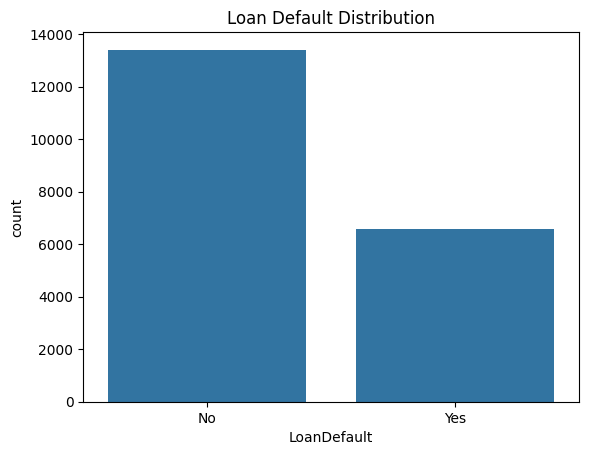

In [11]:
print(df["LoanDefault"].value_counts())
sns.countplot(data=df, x="LoanDefault")
plt.title("Loan Default Distribution")
plt.show()

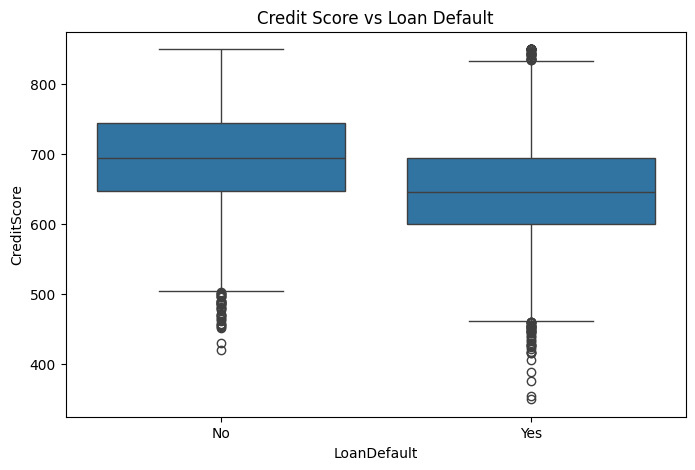

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="LoanDefault", y="CreditScore")
plt.title("Credit Score vs Loan Default")
plt.show()

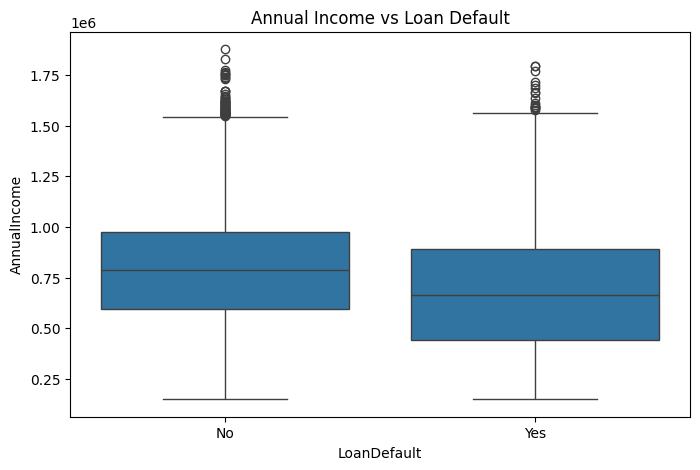

In [13]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="LoanDefault", y="AnnualIncome")
plt.title("Annual Income vs Loan Default")
plt.show()

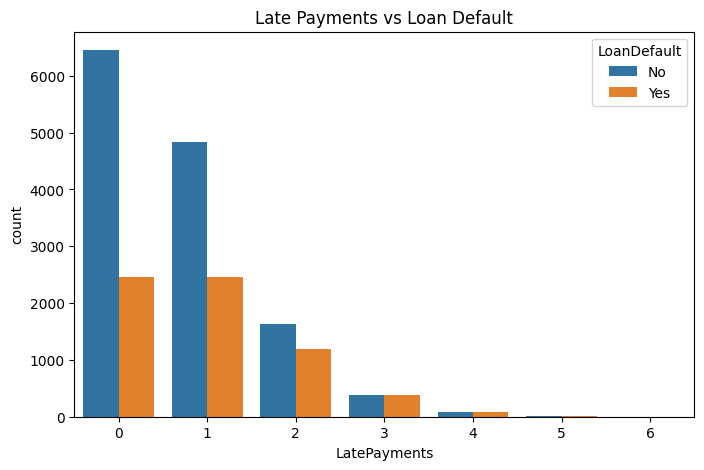

In [14]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="LatePayments", hue="LoanDefault")
plt.title("Late Payments vs Loan Default")
plt.show()

In [15]:
X = df.drop("LoanDefault", axis=1)
y = df["LoanDefault"]
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (20000, 13)
Target Shape: (20000,)


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Age                20000 non-null  int64  
 1   AnnualIncome       20000 non-null  int64  
 2   CreditScore        20000 non-null  int64  
 3   LoanAmount         20000 non-null  int64  
 4   LoanTerm           20000 non-null  int64  
 5   EmploymentYears    20000 non-null  float64
 6   DebtToIncomeRatio  20000 non-null  float64
 7   ExistingLoans      20000 non-null  int64  
 8   LatePayments       20000 non-null  int64  
 9   HomeOwnership      20000 non-null  object 
 10  Education          20000 non-null  object 
 11  MaritalStatus      20000 non-null  object 
 12  LoanPurpose        20000 non-null  object 
 13  LoanDefault        20000 non-null  object 
dtypes: float64(2), int64(7), object(5)
memory usage: 2.1+ MB


In [22]:
numerical_cols=X.select_dtypes(include=["int64","float64"]).columns.tolist()
categorical_cols=X.select_dtypes(include=["object"]).columns.tolist()

In [23]:
print("Numerical Columns:", numerical_cols)
print("Categorical Columns:", categorical_cols)

Numerical Columns: ['Age', 'AnnualIncome', 'CreditScore', 'LoanAmount', 'LoanTerm', 'EmploymentYears', 'DebtToIncomeRatio', 'ExistingLoans', 'LatePayments']
Categorical Columns: ['HomeOwnership', 'Education', 'MaritalStatus', 'LoanPurpose']


# Train-Test Split

In [29]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(16000, 13)
(4000, 13)
(16000,)
(4000,)


In [38]:
numerical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="median")),
    ("scler",StandardScaler())
])

categorical_transformer=Pipeline(steps=[
    ("impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore"))])

In [39]:
preprocessing=ColumnTransformer(transformers=[
    ("num",numerical_transformer,numerical_cals),
    ("cat",categorical_transformer,categorical_cols)
])

# Random Forest Classifier

In [41]:
model=Pipeline(steps=[
    ("preprocessing",preprocessing),
    ("classifier",RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    ))
    
])

model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](2,)","['No','Yes']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['Age','AnnualIncome','CreditScore',...,'Education','MaritalStatus', 'LoanPurpose']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remai

In [42]:
y_pred=model.predict(X_test)

In [44]:
from sklearn.metrics import accuracy_score
accuracy=accuracy_score(y_test,y_pred)
print("Accuracy_score:",accuracy)

Accuracy_score: 0.7335


# Model evaluation

In [45]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, pos_label="Yes")
recall = recall_score(y_test, y_pred, pos_label="Yes")
f1 = f1_score(y_test, y_pred, pos_label="Yes")

print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1 Score :", round(f1, 4))

Accuracy : 0.7335
Precision: 0.5896
Recall   : 0.6509
F1 Score : 0.6187


In [46]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

          No       0.82      0.77      0.80      2671
         Yes       0.59      0.65      0.62      1329

    accuracy                           0.73      4000
   macro avg       0.70      0.71      0.71      4000
weighted avg       0.74      0.73      0.74      4000



- Precision: Out of predicted defaulters, how many actually defaulted?
- Recall: Out of actual defaulters, how many did the model identify?
- F1-score: Balance between precision and recall.
- Support: Number of actual samples in each class.

# Confusion Matrix

In [49]:
cm = confusion_matrix(y_test,y_pred,labels=["No", "Yes"])

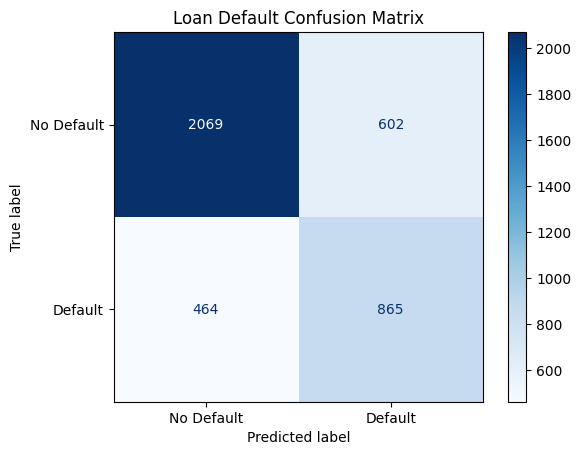

In [50]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"])
disp.plot(cmap="Blues")
plt.title("Loan Default Confusion Matrix")
plt.show()

# ROC-AUC Score

In [52]:
y_prob = model.predict_proba(X_test)[:, 1]
auc = roc_auc_score((y_test == "Yes").astype(int),y_prob)
print("ROC-AUC Score:", round(auc, 4))

ROC-AUC Score: 0.7908


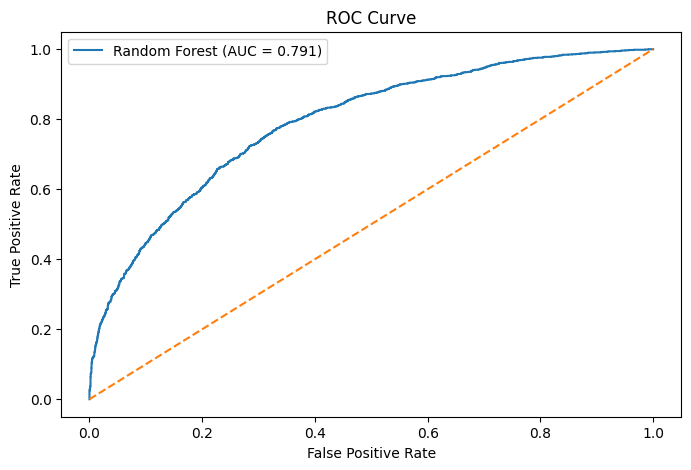

In [53]:
fpr, tpr, thresholds = roc_curve((y_test == "Yes").astype(int),y_prob)
plt.figure(figsize=(8, 5))
plt.plot(fpr, tpr, label=f"Random Forest (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

# Hyperparameter tuning using RandomizedSearchCV

In [56]:
param_grid = {
    "classifier__n_estimators": [100, 200, 300, 400],
    "classifier__max_depth": [None, 10, 15, 20],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 4],
    "classifier__max_features": ["sqrt", "log2"]}

random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=10,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'classifier__max_depth': [None, 10, ...], 'classifier__max_features': ['sqrt', 'log2'], 'classifier__min_samples_leaf': [1, 2, ...], 'classifier__min_samples_split': [2, 5, ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estima

In [57]:
print("Best Parameters:", random_search.best_params_)
print("Best CV F1 Score:", random_search.best_score_)

Best Parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_split': 10, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'log2', 'classifier__max_depth': None}
Best CV F1 Score: nan


# Evaluate tuned model

In [58]:
best_model = random_search.best_estimator_
tuned_pred = best_model.predict(X_test)
print("Tuned Model Classification Report:")
print(classification_report(y_test, tuned_pred))

Tuned Model Classification Report:
              precision    recall  f1-score   support

          No       0.82      0.78      0.80      2671
         Yes       0.60      0.66      0.63      1329

    accuracy                           0.74      4000
   macro avg       0.71      0.72      0.71      4000
weighted avg       0.75      0.74      0.74      4000



In [61]:
print("Tuned Accuracy:", accuracy_score(y_test, tuned_pred))
print("Tuned Precision:", precision_score(y_test, tuned_pred, pos_label="Yes"))
print("Tuned Recall:", recall_score(y_test, tuned_pred, pos_label="Yes"))
print("Tuned F1 Score:", f1_score(y_test, tuned_pred, pos_label="Yes"))

Tuned Accuracy: 0.7385
Tuned Precision: 0.5954146999325691
Tuned Recall: 0.6644093303235515
Tuned F1 Score: 0.628022759601707
